<a href="https://colab.research.google.com/github/shaparve/orange-condition-classification/blob/main/Orange_Condition_Classification_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:

import os
import zipfile

zip_path = "/content/Orange Dataset.zip"
extract_path = "/content/orange_dataset"

if not os.path.exists(zip_path):
    raise FileNotFoundError(
        "Dataset ZIP not found. Upload Orange Dataset.zip first."
    )

with zipfile.ZipFile(zip_path, "r") as archive:
    bad_file = archive.testzip()

    if bad_file is not None:
        raise ValueError(f"Corrupted ZIP entry: {bad_file}")

    archive.extractall(extract_path)

print("ZIP verification successful.")
print("Extracted to:", extract_path)
print("Top-level folders:", os.listdir(extract_path))


ZIP verification successful.
Extracted to: /content/orange_dataset
Top-level folders: ['test', 'train']


In [8]:

from pathlib import Path
import pandas as pd

data_dir = Path("/content/orange_dataset")
class_names = ["blackspot", "canker", "fresh", "grenning"]
splits = ["train", "test"]

rows = []

for split in splits:
    for class_name in class_names:
        class_dir = data_dir / split / class_name

        if not class_dir.is_dir():
            print("Missing folder:", class_dir)
            continue

        image_files = [
            p for p in class_dir.iterdir()
            if p.is_file() and p.suffix.lower() in
            [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        ]

        rows.append({
            "Split": split,
            "Class": class_name,
            "Image_Count": len(image_files)
        })

counts_df = pd.DataFrame(rows)

print(counts_df.to_string(index=False))
print("\nTotal images:", counts_df["Image_Count"].sum())
print("\nCounts by split:")
print(counts_df.groupby("Split")["Image_Count"].sum())


Split     Class  Image_Count
train blackspot          184
train    canker          179
train     fresh          281
train  grenning          347
 test blackspot           22
 test    canker           22
 test     fresh           33
 test  grenning           22

Total images: 1090

Counts by split:
Split
test      99
train    991
Name: Image_Count, dtype: int64


In [9]:

from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in data_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

valid_images = 0
invalid_images = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()
        valid_images += 1
    except Exception as error:
        invalid_images.append((str(path), str(error)))

print("Total image files:", len(image_paths))
print("Valid images:", valid_images)
print("Corrupted/unreadable images:", len(invalid_images))

for path, error in invalid_images[:10]:
    print(path, "->", error)


Total image files: 1090
Valid images: 1090
Corrupted/unreadable images: 0


In [10]:

from collections import Counter
from PIL import Image

dimension_counts = Counter()

for path in image_paths:
    try:
        with Image.open(path) as img:
            dimension_counts[img.size] += 1
    except Exception:
        pass

print("Number of unique image dimensions:", len(dimension_counts))
print("\nMost common dimensions:")

for size, count in dimension_counts.most_common(15):
    print(f"{size[0]} x {size[1]}: {count} images")


Number of unique image dimensions: 150

Most common dimensions:
800 x 800: 776 images
368 x 344: 7 images
426 x 418: 6 images
322 x 294: 5 images
438 x 388: 5 images
488 x 450: 5 images
384 x 368: 5 images
210 x 192: 5 images
492 x 424: 4 images
378 x 372: 4 images
196 x 198: 4 images
212 x 226: 4 images
264 x 224: 4 images
352 x 284: 4 images
340 x 316: 4 images


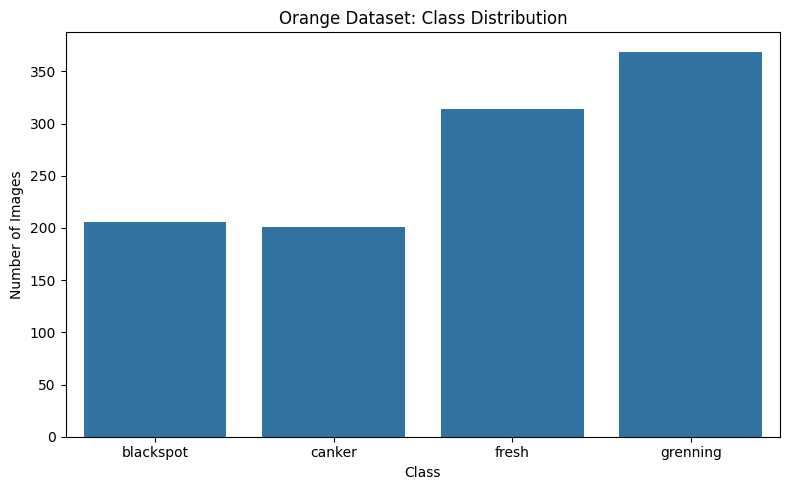

Class counts:
Class
blackspot    206
canker       201
fresh        314
grenning     369
Name: Image_Count, dtype: int64


In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

class_counts = (
    counts_df.groupby("Class")["Image_Count"]
    .sum()
    .reindex(class_names)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Orange Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

print("Class counts:")
print(class_counts)


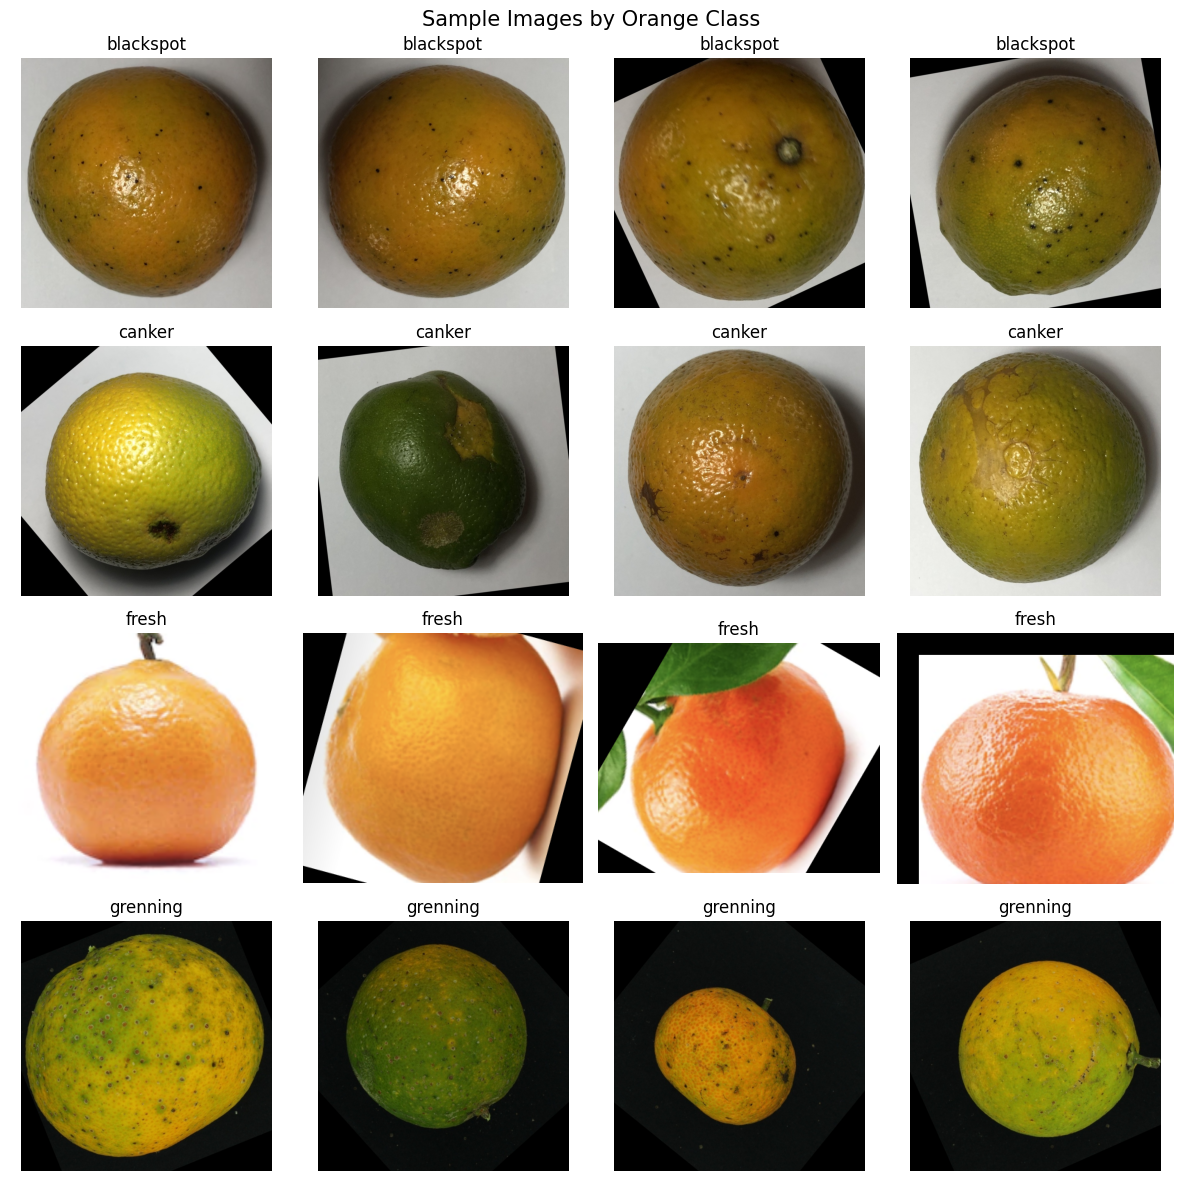

In [12]:

import random
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for row, class_name in enumerate(class_names):
    class_dir = data_dir / "train" / class_name

    samples = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    selected = random.sample(samples, min(4, len(samples)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(selected):
            with Image.open(selected[col]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(class_name)

plt.suptitle("Sample Images by Orange Class", fontsize=15)
plt.tight_layout()
plt.show()


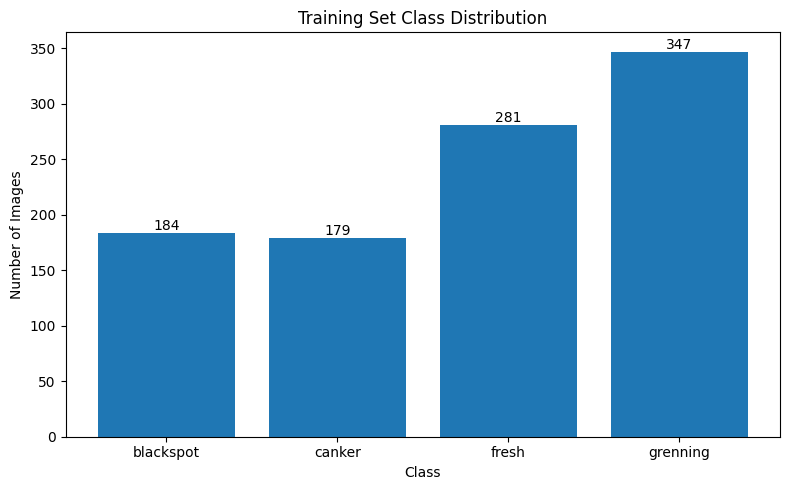

{'blackspot': 184, 'canker': 179, 'fresh': 281, 'grenning': 347}


In [13]:

import matplotlib.pyplot as plt
from pathlib import Path

train_dir = data_dir / "train"

train_counts = {
    class_name: sum(
        1 for p in (train_dir / class_name).iterdir()
        if p.is_file() and p.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )
    for class_name in class_names
}

plt.figure(figsize=(8, 5))
bars = plt.bar(train_counts.keys(), train_counts.values())

plt.title("Training Set Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

for bar, count in zip(bars, train_counts.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print(train_counts)


In [14]:

from pathlib import Path
from sklearn.model_selection import train_test_split
import pandas as pd

train_dir = data_dir / "train"

records = []

for class_name in class_names:
    class_dir = train_dir / class_name

    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            records.append({
                "image_path": str(path),
                "label": class_name
            })

image_df = pd.DataFrame(records)

train_df, val_df = train_test_split(
    image_df,
    test_size=0.20,
    random_state=42,
    stratify=image_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("\nTraining distribution:")
print(train_df["label"].value_counts().reindex(class_names))

print("\nValidation distribution:")
print(val_df["label"].value_counts().reindex(class_names))


Training images: 792
Validation images: 199

Training distribution:
label
blackspot    147
canker       143
fresh        225
grenning     277
Name: count, dtype: int64

Validation distribution:
label
blackspot    37
canker       36
fresh        56
grenning     70
Name: count, dtype: int64


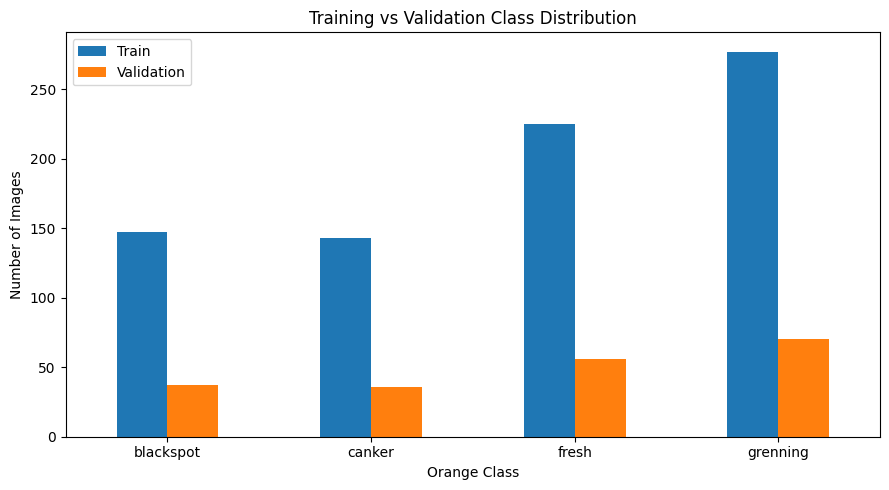

In [15]:

import matplotlib.pyplot as plt
import pandas as pd

split_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts()
}).reindex(class_names)

ax = split_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Training vs Validation Class Distribution")
ax.set_xlabel("Orange Class")
ax.set_ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [16]:

!pip -q install opencv-python-headless scikit-image scikit-learn seaborn



In [18]:

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import local_binary_pattern
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")
print("OpenCV version:", cv2.__version__)


Libraries imported successfully.
OpenCV version: 4.14.0


In [19]:

def extract_features(image_path):
    img = cv2.imread(str(image_path))

    if img is None:
        raise ValueError(f"Could not read image: {image_path}")

    img = cv2.resize(img, (128, 128))

    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

    hist_l = cv2.calcHist(
        [lab], [0], None, [16], [0, 256]
    ).flatten()

    hist_a = cv2.calcHist(
        [lab], [1], None, [16], [0, 256]
    ).flatten()

    hist_b = cv2.calcHist(
        [lab], [2], None, [16], [0, 256]
    ).flatten()

    color_features = np.concatenate([
        hist_l, hist_a, hist_b
    ])

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    lbp = local_binary_pattern(
        gray, P=8, R=1, method="uniform"
    )

    texture_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 11),
        range=(0, 10)
    )

    texture_features = texture_hist.astype(np.float32)
    texture_features /= max(texture_features.sum(), 1)

    return np.concatenate([
        color_features, texture_features
    ]).astype(np.float32)


In [20]:

from tqdm.auto import tqdm

def build_feature_matrix(frame):
    features = []
    labels = []

    for _, row in tqdm(
        frame.iterrows(),
        total=len(frame),
        desc="Extracting features"
    ):
        features.append(extract_features(row["image_path"]))
        labels.append(row["label"])

    return np.vstack(features), np.array(labels)

X_train, y_train = build_feature_matrix(train_df)
X_val, y_val = build_feature_matrix(val_df)

print("Training feature matrix:", X_train.shape)
print("Validation feature matrix:", X_val.shape)


Extracting features:   0%|          | 0/792 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/199 [00:00<?, ?it/s]

Training feature matrix: (792, 58)
Validation feature matrix: (199, 58)


In [21]:

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale")
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

svm_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("SVM training complete.")
print("Random Forest training complete.")


SVM training complete.
Random Forest training complete.


In [22]:

def evaluate_model(model, X, y, model_name):
    predictions = model.predict(X)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y, predictions),
        "Macro Precision": precision_score(
            y, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y, predictions, average="macro", zero_division=0
        )
    }

    print(f"\n{model_name}")
    print(classification_report(
        y, predictions, labels=class_names,
        zero_division=0
    ))

    return metrics, predictions

svm_metrics, svm_val_predictions = evaluate_model(
    svm_model, X_val, y_val, "SVM"
)

rf_metrics, rf_val_predictions = evaluate_model(
    rf_model, X_val, y_val, "Random Forest"
)

validation_results = pd.DataFrame([
    svm_metrics, rf_metrics
])

print("\nValidation comparison:")
print(validation_results.round(4).to_string(index=False))



SVM
              precision    recall  f1-score   support

   blackspot       1.00      0.86      0.93        37
      canker       0.88      1.00      0.94        36
       fresh       1.00      1.00      1.00        56
    grenning       1.00      1.00      1.00        70

    accuracy                           0.97       199
   macro avg       0.97      0.97      0.97       199
weighted avg       0.98      0.97      0.97       199


Random Forest
              precision    recall  f1-score   support

   blackspot       1.00      0.86      0.93        37
      canker       0.88      1.00      0.94        36
       fresh       1.00      1.00      1.00        56
    grenning       1.00      1.00      1.00        70

    accuracy                           0.97       199
   macro avg       0.97      0.97      0.97       199
weighted avg       0.98      0.97      0.97       199


Validation comparison:
        Model  Accuracy  Macro Precision  Macro Recall  Macro F1
          SVM    0.97

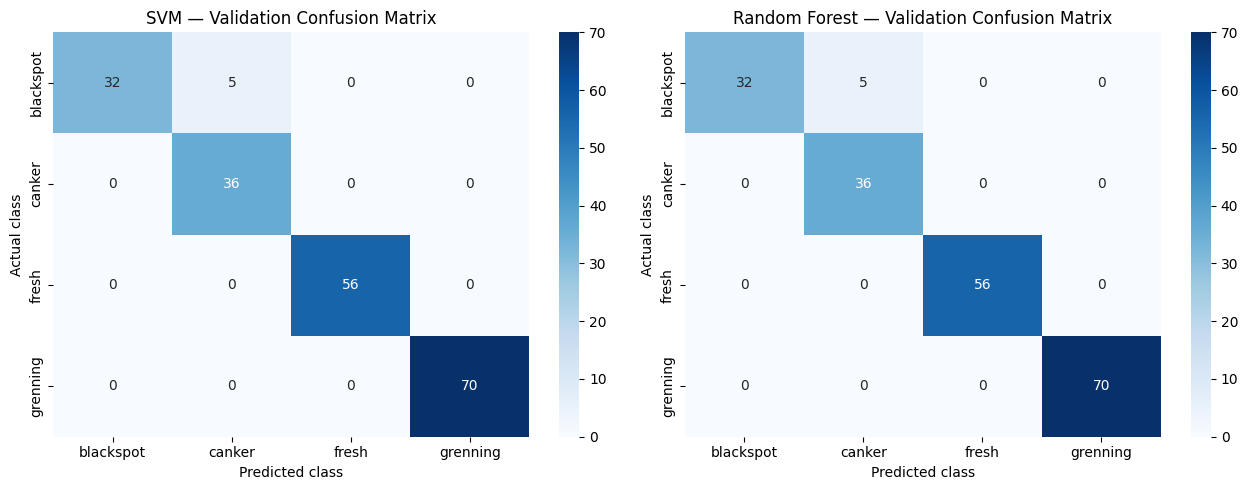

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, predictions, title in [
    (axes[0], svm_val_predictions, "SVM"),
    (axes[1], rf_val_predictions, "Random Forest")
]:
    cm = confusion_matrix(
        y_val, predictions, labels=class_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f"{title} — Validation Confusion Matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()


**Approach 2: MobileNetV2 transfer learning**

In [24]:

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("GPU available:", torch.cuda.is_available())


Device: cuda
GPU available: True


In [25]:

image_size = 224

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.1, contrast=0.1, saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [26]:

class OrangeDataset(Dataset):
    def __init__(self, dataframe, class_names, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.class_names = class_names
        self.class_to_idx = {
            name: idx for idx, name in enumerate(class_names)
        }
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = self.class_to_idx[row["label"]]
        return image, label


train_dataset = OrangeDataset(
    train_df, class_names, train_transform
)

val_dataset = OrangeDataset(
    val_df, class_names, eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 25
Validation batches: 7


In [27]:

weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

for param in model.features.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(in_features, len(class_names))
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

print("MobileNetV2 initialized.")
print("Number of classes:", len(class_names))


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 113MB/s]


MobileNetV2 initialized.
Number of classes: 4


In [28]:

from copy import deepcopy

num_epochs = 5
best_val_loss = float("inf")
best_state = deepcopy(model.state_dict())

history = []

for epoch in range(num_epochs):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total
    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = deepcopy(model.state_dict())

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_acc:.4f}"
    )

model.load_state_dict(best_state)
torch.save(model.state_dict(), "/content/mobilenetv2_orange.pth")

print("Best MobileNetV2 checkpoint saved.")


Epoch 1/5 | Train loss: 0.8748 | Train accuracy: 0.7487 | Val loss: 0.4986 | Val accuracy: 0.9296
Epoch 2/5 | Train loss: 0.3755 | Train accuracy: 0.9533 | Val loss: 0.2942 | Val accuracy: 0.9447
Epoch 3/5 | Train loss: 0.2631 | Train accuracy: 0.9571 | Val loss: 0.2090 | Val accuracy: 0.9799
Epoch 4/5 | Train loss: 0.2062 | Train accuracy: 0.9722 | Val loss: 0.1696 | Val accuracy: 0.9749
Epoch 5/5 | Train loss: 0.1516 | Train accuracy: 0.9785 | Val loss: 0.1443 | Val accuracy: 0.9799
Best MobileNetV2 checkpoint saved.


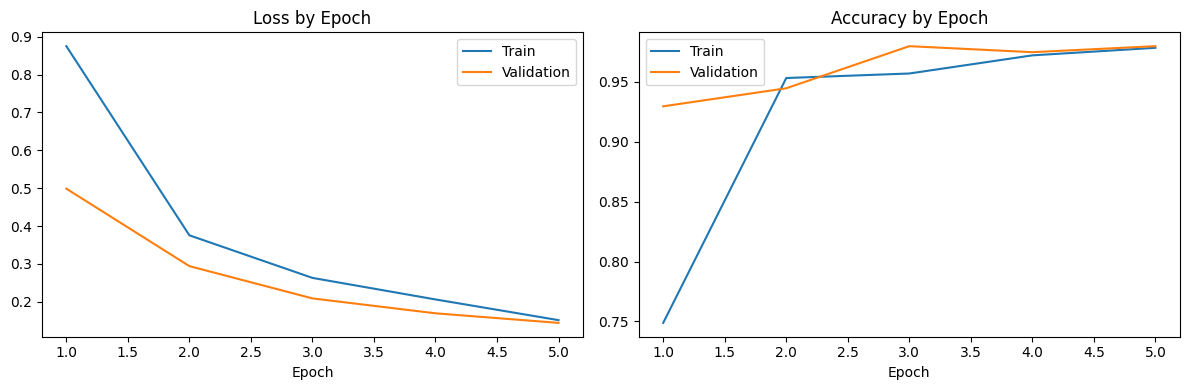

In [29]:

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"], label="Train"
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"], label="Validation"
)
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"], label="Train"
)
axes[1].plot(
    history_df["epoch"], history_df["val_accuracy"], label="Validation"
)
axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

   blackspot       1.00      0.92      0.96        37
      canker       0.95      0.97      0.96        36
       fresh       0.97      1.00      0.98        56
    grenning       1.00      1.00      1.00        70

    accuracy                           0.98       199
   macro avg       0.98      0.97      0.97       199
weighted avg       0.98      0.98      0.98       199

Validation accuracy: 0.9799
Macro precision: 0.9779
Macro recall: 0.9728
Macro F1: 0.9748


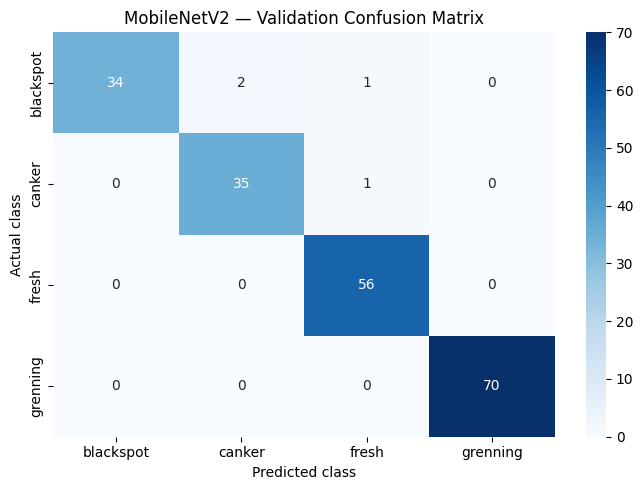

In [30]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("Validation accuracy:",
      round(accuracy_score(y_true, y_pred), 4))
print("Macro precision:",
      round(precision_score(y_true, y_pred, average="macro",
                            zero_division=0), 4))
print("Macro recall:",
      round(recall_score(y_true, y_pred, average="macro",
                         zero_division=0), 4))
print("Macro F1:",
      round(f1_score(y_true, y_pred, average="macro",
                     zero_division=0), 4))

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(class_names)))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("MobileNetV2 — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [31]:

dl_val_metrics = {
    "Model": "MobileNetV2",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
}

comparison_df = pd.concat([
    validation_results,
    pd.DataFrame([dl_val_metrics])
], ignore_index=True)

print(comparison_df.round(4).to_string(index=False))


        Model  Accuracy  Macro Precision  Macro Recall  Macro F1
          SVM    0.9749           0.9695        0.9662    0.9657
Random Forest    0.9749           0.9695        0.9662    0.9657
  MobileNetV2    0.9799           0.9779        0.9728    0.9748


In [32]:

from pathlib import Path
import pandas as pd

test_dir = data_dir / "test"
test_records = []

for class_name in class_names:
    class_dir = test_dir / class_name

    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            test_records.append({
                "image_path": str(path),
                "label": class_name
            })

test_df = pd.DataFrame(test_records)

print("Test images:", len(test_df))
print("\nTest distribution:")
print(test_df["label"].value_counts().reindex(class_names))

assert len(test_df) == 99, (
    f"Expected 99 test images, found {len(test_df)}"
)


Test images: 99

Test distribution:
label
blackspot    22
canker       22
fresh        33
grenning     22
Name: count, dtype: int64


In [33]:

X_test, y_test = build_feature_matrix(test_df)

svm_test_metrics, svm_test_predictions = evaluate_model(
    svm_model, X_test, y_test, "SVM Test"
)

rf_test_metrics, rf_test_predictions = evaluate_model(
    rf_model, X_test, y_test, "Random Forest Test"
)


Extracting features:   0%|          | 0/99 [00:00<?, ?it/s]


SVM Test
              precision    recall  f1-score   support

   blackspot       0.95      0.91      0.93        22
      canker       0.91      0.95      0.93        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99


Random Forest Test
              precision    recall  f1-score   support

   blackspot       0.91      0.95      0.93        22
      canker       0.95      0.91      0.93        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99



In [34]:

test_dataset = OrangeDataset(
    test_df, class_names, eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

model.eval()

dl_test_true = []
dl_test_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        dl_test_pred.extend(predictions)
        dl_test_true.extend(labels.numpy())

dl_test_true = np.array(dl_test_true)
dl_test_pred = np.array(dl_test_pred)

print(classification_report(
    dl_test_true,
    dl_test_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


              precision    recall  f1-score   support

   blackspot       0.91      0.91      0.91        22
      canker       0.90      0.82      0.86        22
       fresh       0.94      1.00      0.97        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.94        99
   macro avg       0.94      0.93      0.93        99
weighted avg       0.94      0.94      0.94        99



In [35]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

test_results = pd.DataFrame([
    calculate_metrics(
        y_test, svm_test_predictions, "SVM"
    ),
    calculate_metrics(
        y_test, rf_test_predictions, "Random Forest"
    ),
    calculate_metrics(
        dl_test_true, dl_test_pred, "MobileNetV2"
    )
])

print(test_results.round(4).to_string(index=False))


        Model  Accuracy  Macro Precision  Macro Recall  Macro F1
          SVM    0.9697           0.9664        0.9659    0.9659
Random Forest    0.9697           0.9664        0.9659    0.9659
  MobileNetV2    0.9394           0.9380        0.9318    0.9342


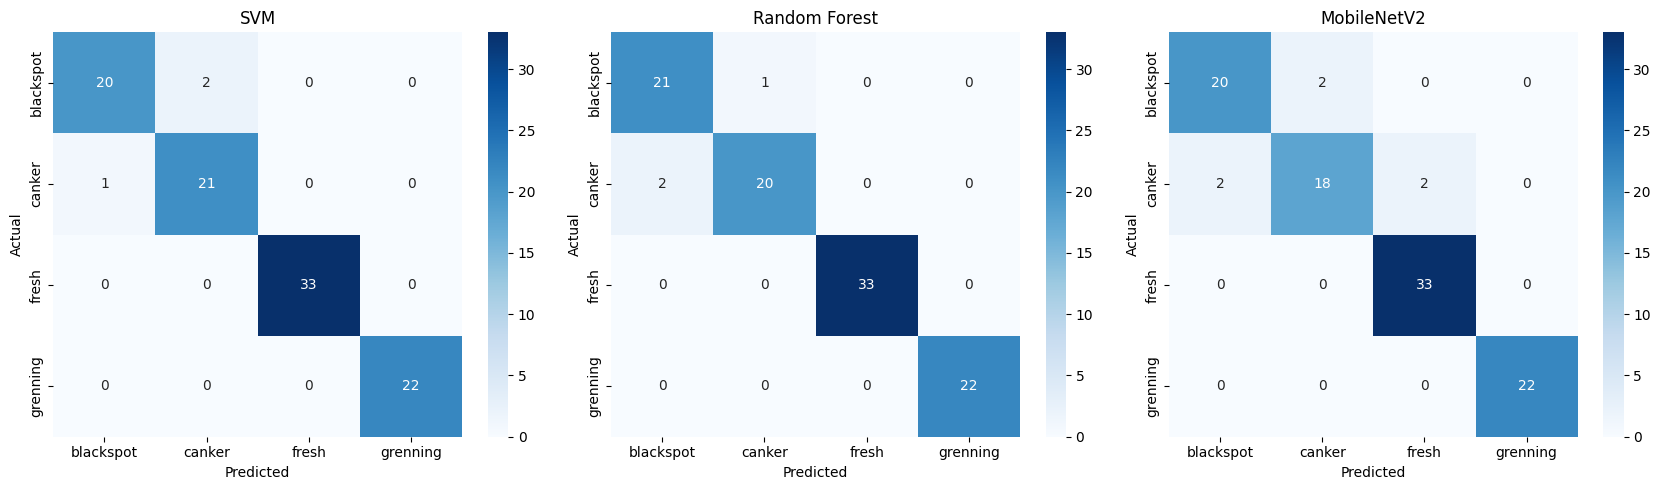

In [38]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

predictions_list = [
    (
        np.array(y_test),
        np.array(svm_test_predictions),
        "SVM"
    ),
    (
        np.array(y_test),
        np.array(rf_test_predictions),
        "Random Forest"
    ),
    (
        np.array([class_names.index(x) for x in y_test]),
        np.array(dl_test_pred),
        "MobileNetV2"
    )
]

for ax, (actual, predicted, name) in zip(axes, predictions_list):
    cm = confusion_matrix(
        actual,
        predicted,
        labels=class_names if name != "MobileNetV2"
        else list(range(len(class_names)))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [39]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

y_test_num = np.array([
    class_names.index(label) for label in y_test
])

svm_pred_num = np.array([
    class_names.index(label) for label in svm_test_predictions
])

rf_pred_num = np.array([
    class_names.index(label) for label in rf_test_predictions
])

predictions = {
    "SVM": (y_test_num, svm_pred_num),
    "Random Forest": (y_test_num, rf_pred_num),
    "MobileNetV2": (dl_test_true, dl_test_pred)
}

final_results = []

for name, (actual, predicted) in predictions.items():
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Macro Precision": precision_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            actual, predicted, average="macro", zero_division=0
        )
    })

final_results_df = pd.DataFrame(final_results)

print(final_results_df.round(4).to_string(index=False))


        Model  Accuracy  Macro Precision  Macro Recall  Macro F1
          SVM    0.9697           0.9664        0.9659    0.9659
Random Forest    0.9697           0.9664        0.9659    0.9659
  MobileNetV2    0.9394           0.9380        0.9318    0.9342


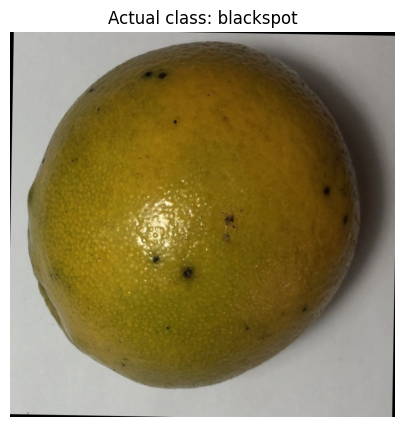

SVM prediction: blackspot
Random Forest prediction: blackspot
MobileNetV2 prediction: blackspot
MobileNetV2 confidence: 97.05%


In [40]:

import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

sample_path = test_df.iloc[0]["image_path"]

features = extract_features(sample_path).reshape(1, -1)
svm_prediction = svm_model.predict(features)[0]
rf_prediction = rf_model.predict(features)[0]

with Image.open(sample_path) as image:
    display_image = image.convert("RGB")
    input_tensor = eval_transform(display_image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]
    dl_index = probabilities.argmax().item()

dl_prediction = class_names[dl_index]
confidence = probabilities[dl_index].item()

plt.figure(figsize=(5, 5))
plt.imshow(display_image)
plt.axis("off")
plt.title(f"Actual class: {test_df.iloc[0]['label']}")
plt.show()

print("SVM prediction:", svm_prediction)
print("Random Forest prediction:", rf_prediction)
print("MobileNetV2 prediction:", dl_prediction)
print(f"MobileNetV2 confidence: {confidence:.2%}")


In [41]:

import os
import joblib
import torch

os.makedirs("/content/orange_classification_models", exist_ok=True)

joblib.dump(
    svm_model,
    "/content/orange_classification_models/svm_model.joblib"
)

joblib.dump(
    rf_model,
    "/content/orange_classification_models/random_forest_model.joblib"
)

torch.save(
    model.state_dict(),
    "/content/orange_classification_models/mobilenetv2_model.pth"
)

print("All three models saved successfully.")


All three models saved successfully.


In [42]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/orange_classification_models",
    "zip",
    "/content/orange_classification_models"
)

files.download("/content/orange_classification_models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:

import time
import numpy as np

sample_path = test_df.iloc[0]["image_path"]
sample_features = extract_features(sample_path).reshape(1, -1)

with Image.open(sample_path) as image:
    sample_tensor = eval_transform(
        image.convert("RGB")
    ).unsqueeze(0).to(device)

def benchmark_classical(model_to_test, features, repetitions=100):
    for _ in range(5):
        model_to_test.predict(features)

    start = time.perf_counter()

    for _ in range(repetitions):
        model_to_test.predict(features)

    elapsed = time.perf_counter() - start
    return elapsed / repetitions * 1000

svm_ms = benchmark_classical(svm_model, sample_features)
rf_ms = benchmark_classical(rf_model, sample_features)

model.eval()

with torch.no_grad():
    for _ in range(5):
        model(sample_tensor)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for _ in range(100):
        with torch.no_grad():
            model(sample_tensor)

    if device.type == "cuda":
        torch.cuda.synchronize()

    dl_ms = (time.perf_counter() - start) / 100 * 1000

print(f"SVM prediction: {svm_ms:.3f} ms/image")
print(f"Random Forest prediction: {rf_ms:.3f} ms/image")
print(f"MobileNetV2 prediction: {dl_ms:.3f} ms/image")
print("Runtime device:", device)


SVM prediction: 1.013 ms/image
Random Forest prediction: 80.953 ms/image
MobileNetV2 prediction: 11.161 ms/image
Runtime device: cuda
